# 00 – Main: run the whole project

Runs the steps of the project in order (see `report/project_flow_with_files.png`). Select the kernel and choose **Run All**.
All steps take about 11 minutes, most of it `04_models.ipynb` (about 6) and `04b_model_choice.ipynb` (about 5).

| Step | Notebook | Tasks | Output |
|---|---|---|---|
| 1 Data | `01_preprocess.ipynb` | 6–12 | `data/processed/building_clean.csv` |
| 2 Split & pipeline | `02_split_pipeline.ipynb` | 16, checks 17, 19 | `data/processed/cv.csv`, `test.csv` |
| 3 Explore | `03_describe.ipynb` | 13–15 | descriptive tables and figures (reads `cv.csv`, so it runs after the split) |
| 4 Models | `04_models.ipynb` | 18, 20–23 | `output/tables/models_*.csv` |
| 4b Model choice | `04b_model_choice.ipynb` | 26 (choice) | `output/tables/choice_*.csv` |
| 5 Evaluation | `05_evaluation.ipynb` | 24, 26, 27 | `output/tables/evaluation_*.csv` |

`%run` runs every notebook in the memory of this one, so a variable from an earlier notebook is still there in a
later one. Each notebook must therefore also run on its own: restart the kernel, open it and choose Run All (task 33).

In [1]:
%pip install nbformat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [nbformat]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# reload changed .py files (cv.py, pipeline.py, metrics.py, config.py) before every cell,
# so a running kernel never uses an old version of them
%load_ext autoreload
%autoreload 2

import numpy as np
from config import SEED  # the one project seed, defined in config.py

np.random.seed(SEED)

Heating file: 249398 rows, 21206 buildings, years 0 to 2026
Register: 87421 rows, 87421 buildings
Rows that are duplicated: 1047
Do all copies have the same value? True
Rows after cleaning: 248859
Buildings with a 3-year average from 2023 : 16587


,EGID,ref_year,y,heated_floor_area,building_type
70267,1013338,2023,555.0,1377,Eglise
172708,2036675,2023,370.0,253,Habitation un logement
69988,1013417,2023,480.0,2541,Hab. - rez activités
70169,1013266,2023,517.0,1055,Habitation - activités
171981,2036972,2023,455.0,1739,Bureaux
...,...,...,...,...,...
203096,3132099,2026,314.0,810,Hab plusieurs logements
23279,1006454,2026,314.0,1069,Habitation - activités
230213,295119457,2026,156.0,1490,Hab plusieurs logements
144299,1030897,2026,212.0,1642,Habitation - activités


Buildings removed as implausible: 25
Buildings kept: 16562
    construction_period_code construction_period  energy_source_code energy_source
0                        NaN                 NaN                 NaN           NaN
1                     8017.0           1986-1990              7530.0        Heizöl
2                     8014.0           1961-1970              7530.0        Heizöl
4                     8015.0           1971-1980              7530.0        Heizöl
6                     8013.0           1946-1960              7530.0        Heizöl
7                     8016.0           1981-1985              7530.0        Heizöl
9                     8013.0           1946-1960              7520.0           Gas
11                    8017.0           1986-1990              7520.0           Gas
Missing values after this step, among buildings with a target:
construction_period_code     83
energy_source_code          188
heating_system_code         414
building_class_code          13
flo

,count,median
ANNEE,,
2011,15626,499.0
2012,16061,508.0
2013,16245,511.0
2014,16260,495.0
2015,15851,490.0
2016,15819,477.0
2017,15817,476.0
2018,15902,486.0
2019,15941,470.0



Target by reference year:
          count  median
ref_year               
2023        816   422.0
2024       1390   409.0
2025       8036   387.0
2026       6320   382.0

Same buildings, period ending in 2023 vs 2026: 6067 buildings, median 432.0 -> 383.0 | median change: -43.0

Option B (only periods ending in 2025) would keep: 14267 buildings, 1077 houses
Option A (latest period from 2023 on) keeps: 16562 buildings, 1531 houses


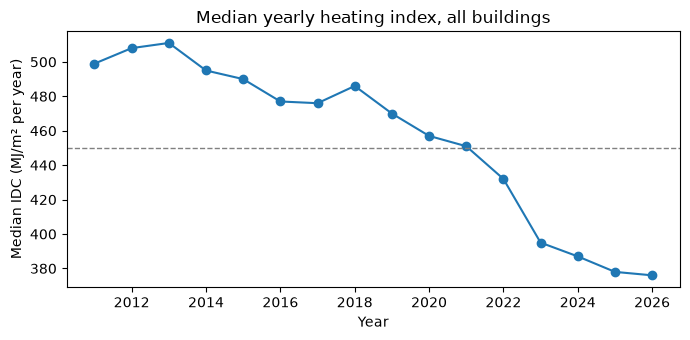

          all buildings (%)  houses (%)
ref_year                               
2023                    4.9        12.3
2024                    8.4        15.2
2025                   48.5        50.8
2026                   38.2        21.8

Share ending in 2025 or 2026, all buildings: 86.7 %
Share ending in 2025 or 2026, houses: 72.6 %

Houses by reference year:
          count  median
ref_year               
2023        188   450.5
2024        232   381.0
2025        777   421.0
2026        334   413.0
Removed, not in the register: 107
Removed, not an existing building: 3
Buildings left: 16452 | houses: 1531
Houses: 1531
Houses that switched: 65
Share of houses that switched: 4.2 %
Houses with other in their switch: 20

energy_group
other → heat pump      16
district heat → oil    13
gas → heat pump         9
oil → heat pump         6
gas → gas               4

Buildings removed because they switched: 697
Houses removed because they switched: 65
Buildings left: 15755 | Houses left: 14

In [3]:
%run 01_preprocess.ipynb

In [4]:
%run 02_split_pipeline.ipynb

Buildings: 14827 | houses: 1366 | groups: 12866
Test set: 2117 buildings, 195 houses
Buildings without a fold (should be the test set): 2117


,buildings,houses,groups,share of buildings (%),house share (%),houses above 450 (%)
part,,,,,,
0,2542,234,2207,17.1,9.2,36.3
1,2545,235,2205,17.2,9.2,39.6
2,2541,234,2209,17.1,9.2,37.6
3,2541,234,2202,17.1,9.2,38.9
4,2541,234,2203,17.1,9.2,37.6
test,2117,195,1840,14.3,9.2,35.9


Groups split across parts: 0
Saved cv.csv: 12710 buildings | test.csv: 2117 buildings
1.0
0.5
0.75
0.0
Overall mean: 400.0
{'A|gas': 300.0, 'B|oil': 520.0, 'C|wood': 440.0}
[300. 400.]
{'A|gas': 200.0, 'B|oil': 1000.0, 'C|wood': 600.0}
Columns after preprocessing: 92
Missing values after preprocessing: 0
Expert-rule column present: True

Overall mean, learned: 395.04 | folds 1-4: 395.04 | all buildings in cross-validation: 395.84
Buildings counted in the expert rule: 10168 | buildings in folds 1-4: 10168


Above 450, all buildings: 29.0 %
Above 450, houses:        38.0 %
Median, all buildings: 390.0 | houses: 417.0


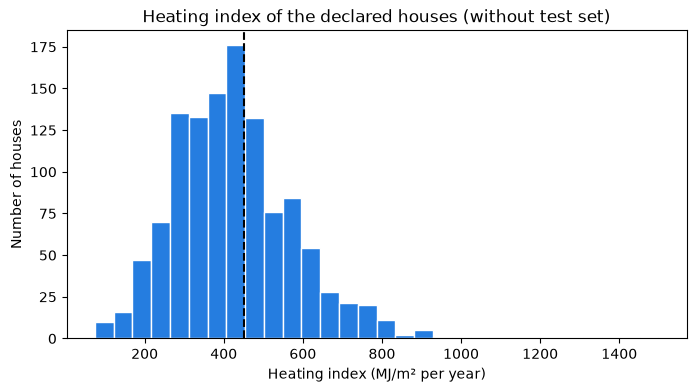

                          buildings  median  above_450
building_class                                        
Gebäude mit 2 Wohnungen         333   422.0       40.2
Wohngeb.f.Gemeinschaften        100   419.0       41.0
Behälter, Silo, Lager           102   418.0       45.1
Gebäude mit 1 Wohnung           838   415.0       37.1
Gebäude mit 3+ Whgen           9416   393.0       27.9
Kultur-/Freizeitstätte          103   390.0       35.9
Gross- und Einzelhandel         184   364.0       32.1
Industriegebäude                287   347.0       26.8
Schul-/Hochschulgebäude         332   328.0       19.6
Bürogebäude                     556   321.0       19.2
             houses  median  above_450
era                                   
before 1946     310   444.5       48.4
1946-1980       327   446.0       48.6
1981-2000       286   400.5       31.5
after 2000      248   343.0       18.5


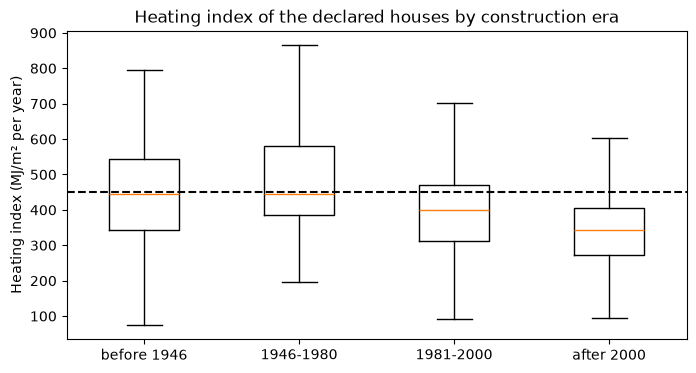

               houses  median  above_450
energy_group                            
oil               380   446.0       45.3
gas               600   413.5       41.2
district heat      15   360.0       13.3
electric           14   312.0       14.3
wood               23   302.0       21.7
other             108   295.5       10.2
heat pump          31   272.0       19.4
                          step  buildings
0  fewer than 5 heat consumers      23123
1              without a value      22439
2              in the register      22098
3            existing building      22083
4        house (1-2 dwellings)      21377
Declared houses: 1171 | undeclared houses: 21377
                                    declared (%)  undeclared (%)  difference
era           1946-1980                     27.9            28.9         1.0
              1981-2000                     24.4            27.2         2.8
              after 2000                    21.2            21.1        -0.1
              before 1

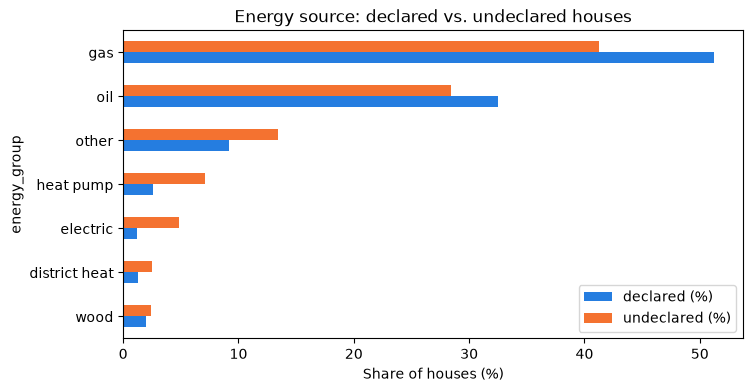

In [5]:
%run 03_describe.ipynb

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


Buildings in cross-validation: 12710 | of which houses: 1171
Training mean, baseline                            
Expert rule, baseline                              
Linear regression, reference                       
Linear regression, no expert rule                  
Ridge, reference                                   best alpha = 562
Ridge, no expert rule                              best alpha = 0.01
Lasso, reference                                   best alpha = 0.001
Lasso, no expert rule                              best alpha = 0.631
Logistic regression, reference                     best C = 10
Logistic regression, no expert rule                best C = 10
Linear regression, no municipality                 
Linear regression, no heating                      
Linear regression, no heating, no municipality     
Ridge, no municipality                             best alpha = 0.01
Ridge, no heating                                  best alpha = 31.6
Ridge, no heating, no municipality

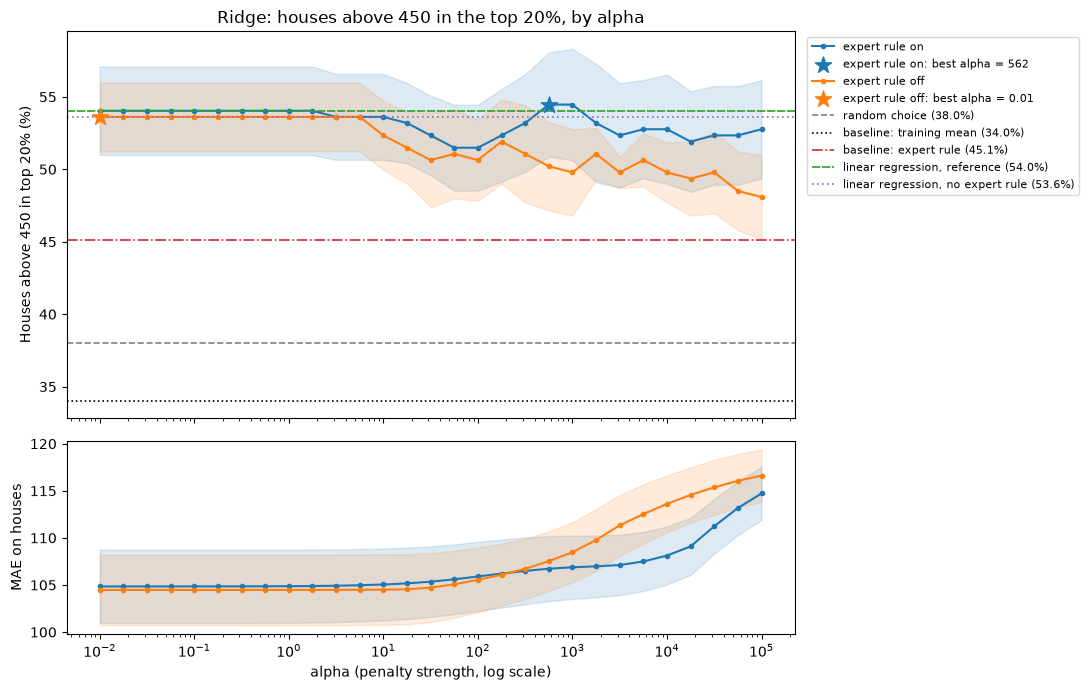

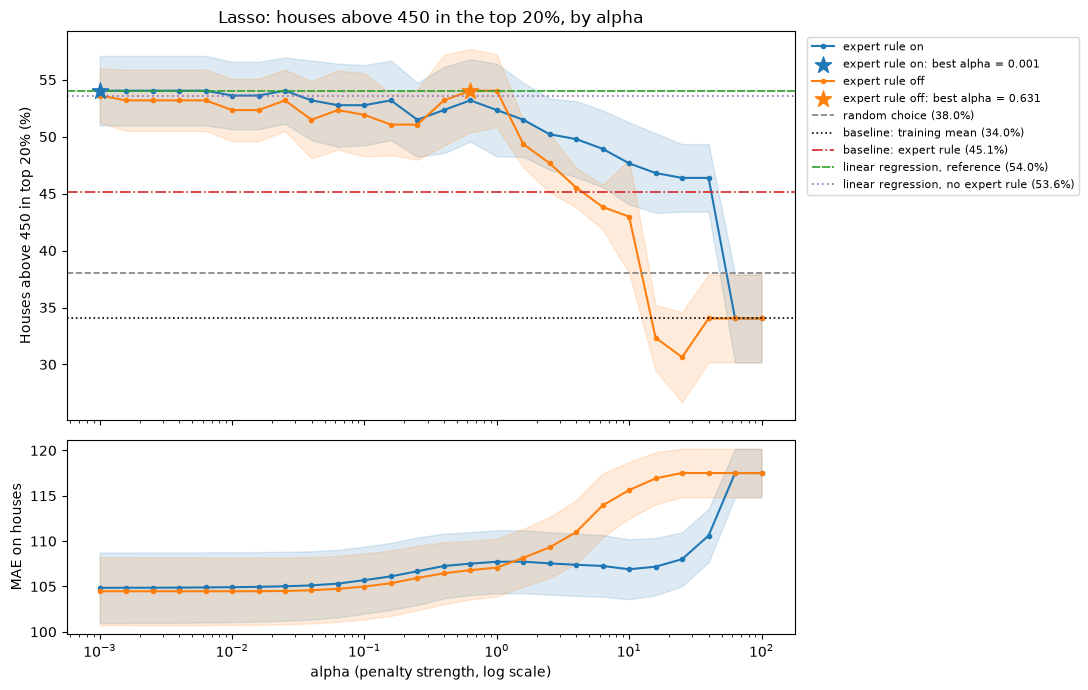

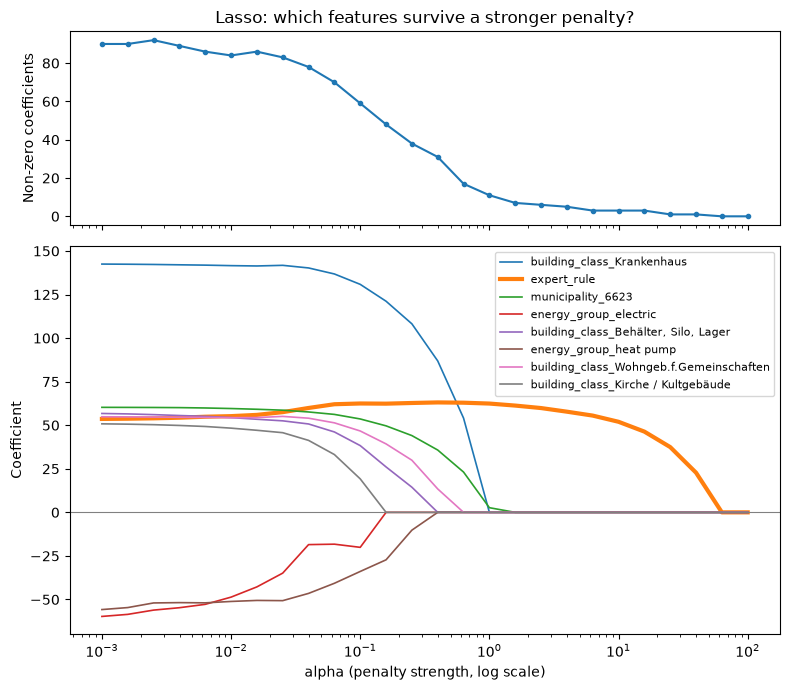

Houses above 450: 38.0 %
All buildings above 450: 29.0 %


,expert_rule,C,top 20%: above 450 (%),± SE
0,True,0.001,53.2,4.1
1,True,0.010,51.9,3.6
2,True,0.100,52.8,2.5
3,True,1.000,53.2,2.7
4,True,10.000,53.6,2.9
5,True,100.000,53.6,2.9
6,False,0.001,49.8,1.6
7,False,0.010,53.2,3.4
8,False,0.100,51.5,2.6
9,False,1.000,53.6,2.0


Best: Logistic regression, no expert rule | C = 10.0


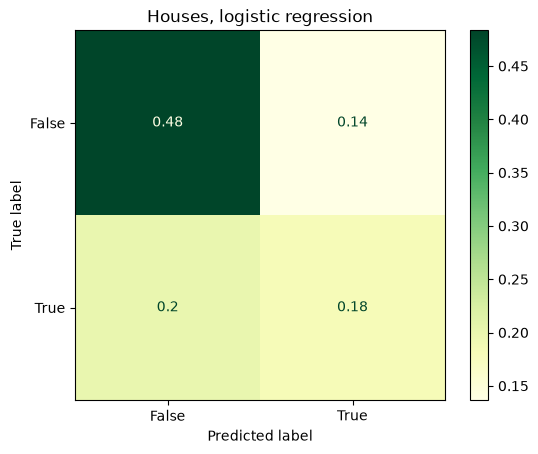

Accuracy : 0.664 | baseline: 0.62
Precision: 0.57
Recall   : 0.476
F1       : 0.519
AUC      : 0.687
AUC logistic: 0.687


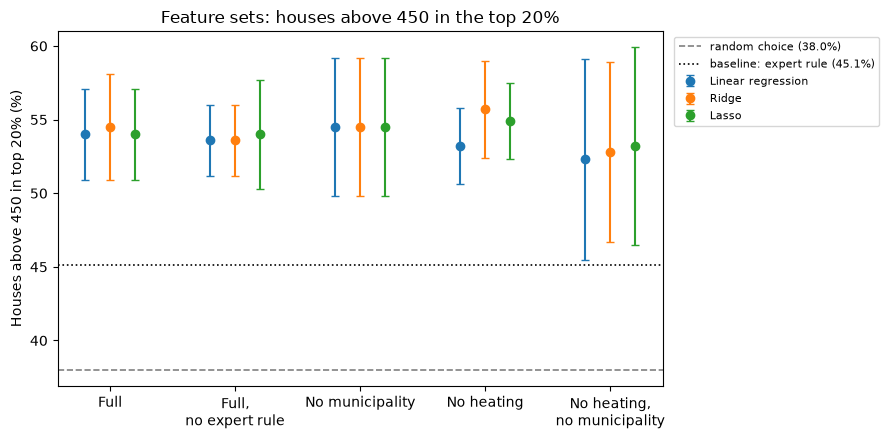

Linear regression
      A: all buildings (%)  B: houses only (%)  B minus A (points)
fold                                                              
0                     46.8                55.3                 8.5
1                     46.8                55.3                 8.5
2                     61.7                55.3                -6.4
3                     57.4                68.1                10.6
4                     57.4                55.3                -2.1
Houses only better in 3 of 5 folds, worse in 2 of 5 folds | mean difference +3.8 points (± 3.4 SE)

Ridge
      A: all buildings (%)  B: houses only (%)  B minus A (points)
fold                                                              
0                     46.8                57.4                10.6
1                     53.2                59.6                 6.4
2                     61.7                59.6                -2.1
3                     63.8                68.1                 4.3
4    

,n,mean error,± 95%,clear,second model: mean error
construction_period,,,,,
Vor 1919,203,-1.5,19.2,False,-6.0
1919-1945,107,-8.0,34.5,False,4.0
1946-1960,74,3.7,40.0,False,32.7
1961-1970,107,-1.2,33.4,False,-1.4
1971-1980,146,1.2,20.1,False,-3.1
1981-1985,62,-6.2,33.2,False,8.4
1986-1990,92,-0.3,22.0,False,-3.6
1991-1995,71,-4.0,25.3,False,6.4
1996-2000,61,-2.2,32.8,False,20.8


Energy group


,n,mean error,± 95%,clear,second model: mean error
energy_group,,,,,
gas,600,-2.4,11.1,False,-7.7
heat pump,31,50.6,38.1,True,-5.6
oil,380,0.4,14.2,False,9.7
other,108,4.2,22.7,False,1.5
wood,23,-9.6,48.8,False,23.5


Heating system


,n,mean error,± 95%,clear,second model: mean error
heating_system,,,,,
Heizkessel (gen.) für mehr. Geb.,72,7.3,29.1,False,20.0
Heizkessel (gene.) für ein Geb.,684,-0.3,10.4,False,-4.5
Heizkessel kond. für ein Geb.,145,-1.8,23.5,False,12.1
Heizkessel nicht kond. für ein Geb.,99,-15.0,28.8,False,-3.2
Wärmepumpe für ein Geb.,108,9.3,23.5,False,-6.6
unknown,28,28.2,34.7,False,19.1


... (8 outputs left out)

Construction period × energy group


,,n,mean error,± 95%,clear,second model: mean error
construction_period,energy_group,,,,,
Nach 2015,other,47,-32.0,29.8,True,-16.1


Reference year (not in the model)


,n,mean error,± 95%,clear,second model: mean error
ref_year,,,,,
2023,138,-51.3,26.7,True,-40.1
2024,173,19.6,20.1,False,12.0
2025,598,-2.8,11.4,False,-3.2
2026,262,23.1,14.2,True,16.4


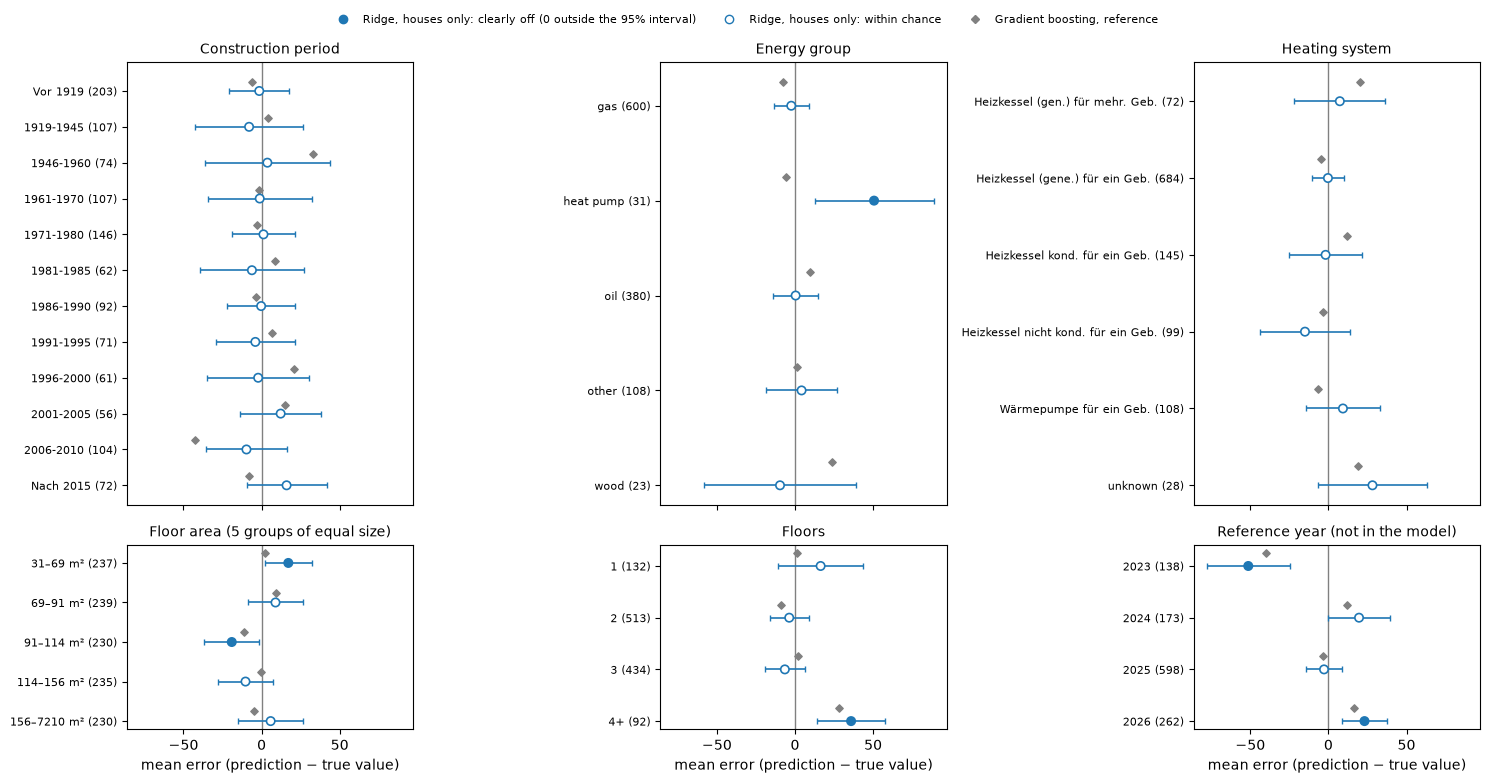

,setting,top 20%: above 450 (%),± SE,top 10%: above 450 (%),top 20%: captured (%),MAE,all buildings: top 20%: above 450 (%),all buildings: MAE
variant,,,,,,,,
"Ridge, houses only",alpha = 31.6,60.4,2.0,54.4,31.9,107.1,NaN,NaN
"Ridge, houses only, spline area",alpha = 5.62e+04,60.9,2.8,65.5,32.2,116.3,NaN,NaN


,"Ridge, houses only (%)","Ridge, houses only, spline area (%)",spline minus straight line (points)
fold,,,
0,57.4,63.8,6.4
1,59.6,51.1,-8.5
2,59.6,59.6,0.0
3,68.1,68.1,0.0
4,57.4,61.7,4.3


Spline vs. straight line: {'difference (points)': np.float64(0.4), '± SE': np.float64(2.6), 'better in': '2 of 5 folds', 'worse in': '1 of 5 folds'}


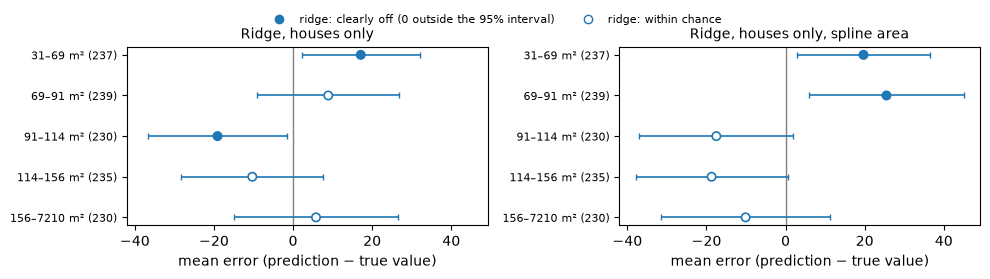

alpha = 10.0 | house deviations: 26


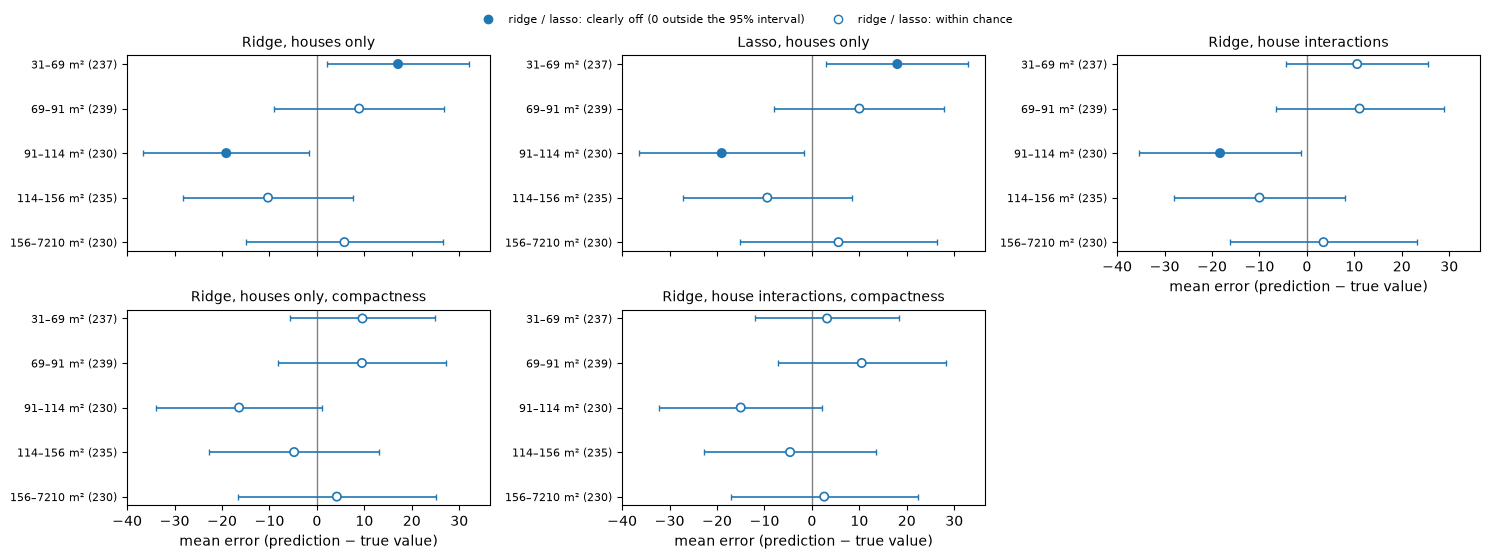

Saved: 28 variants, 12710 out-of-fold predictions each


In [6]:
%run 04_models.ipynb

In [ ]:
%run 04b_model_choice.ipynb

Model analysed: Ridge, houses only
Buildings: 12710 | houses: 1171
Houses
       true value  prediction
count      1171.0      1171.0
mean        426.0       426.0
std         152.0        72.0
min          74.0       207.0
25%         321.0       378.0
50%         417.0       428.0
75%         514.0       481.0
max        1499.0       578.0

All buildings
       true value  prediction
count     12710.0     12710.0
mean        396.0       402.0
std         126.0        72.0
min          50.0       118.0
25%         319.0       353.0
50%         390.0       406.0
75%         465.0       454.0
max        1499.0       595.0

Predictions below 50: 0 | below 0: 0 | above 1,500: 0
Spread of predictions vs. true values (houses): 72 vs. 152


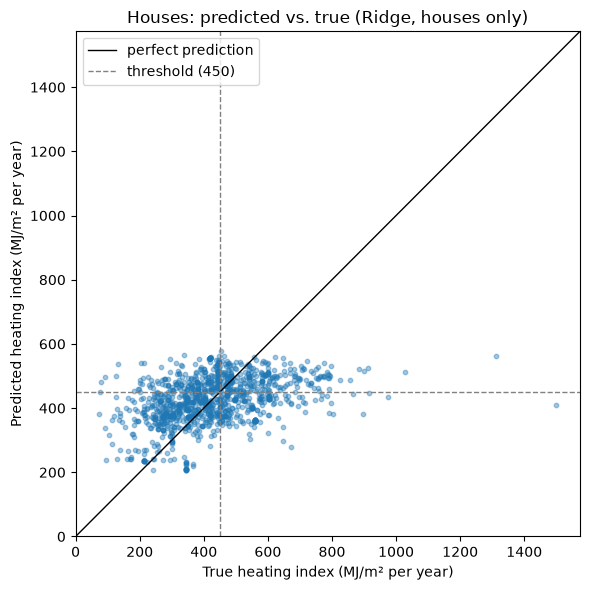

              count  mean_error    mae
true band                             
1: up to 250    115       171.6  172.2
2: 250–350      271        87.4  103.2
3: 350–450      340        33.7   58.3
4: 450–550      224       -46.2   62.3
5: 550–700      164      -154.3  154.3
6: above 700     57      -324.9  324.9


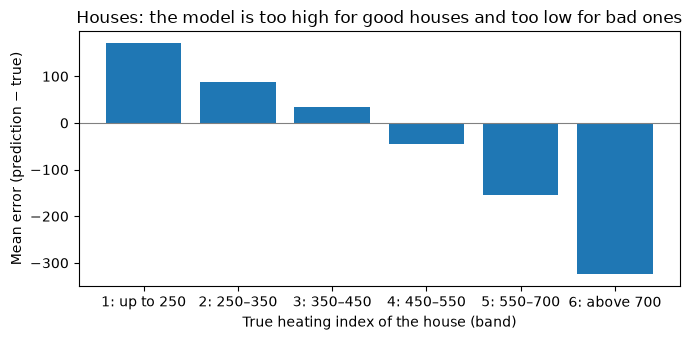

outcome
correctly left out    633
missed                303
hit                   142
false alarm            93

Share of hits among contacted houses: 60.4 % (should be close to 54% from task 20)
True value of false alarms:
count     93.0
mean     388.0
std       75.0
min       91.0
25%      370.0
50%      418.0
75%      443.0
max      448.0

False alarms just below the threshold (400–450): 59 of 93

True and predicted value of missed problem houses:
            y   pred
count   303.0  303.0
mean    563.0  426.0
std     107.0   44.0
min     451.0  278.0
25%     484.0  393.0
50%     548.0  430.0
75%     602.0  460.0
max    1499.0  499.0
Construction period (% of each column)
outcome               hit  false alarm  missed  correctly left out
construction_period                                               
Vor 1919             22.5          8.6    20.8                15.8
1919-1945             9.9         15.1    13.5                 6.0
1946-1960             2.8         18.3     8.9   

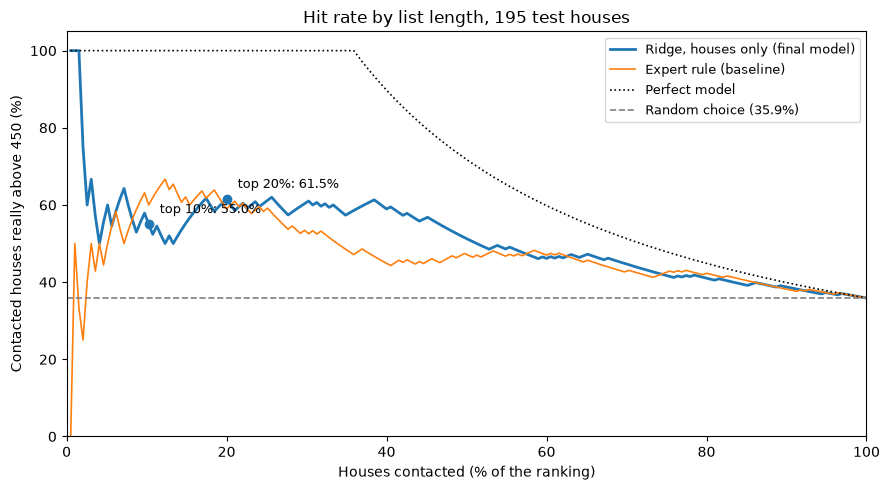

In [7]:
%run 05_evaluation.ipynb